In [1]:
# Loading dataset

# importing modules
import tensorflow as tf

# making dataset to directory
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "path/to/Balanced Dataset",
    shuffle=True,
    batch_size=32,
    image_size=(299, 299),
)
print(dataset)
# after this step the image folder is converted into directory and each image is converted into size of (299 x 299)

Found 13806 files belonging to 78 classes.
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 299, 299, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


In [2]:
# extracting the category names from the dataset
labels = dataset.class_names
# print(labels)
print("The different categories of medicinal plants used in this project are :")
print(", ".join(labels))
print("The total number of categories are :", len(labels))

The different categories of medicinal plants used in this project are :
Aloevera, Amla, Amruthaballi, Arali, Astma_weed, Balloon_Vine, Bamboo, Beans, Betel, Bhrami, Bringaraja, Caricature, Castor, Catharanthus, Chakte, Chikoo-pala, Chilly, Citron lime, Coffee, Common rue, Coriender, Curry, Doddpathre, Drumstick, Ekka, Eucalyptus, Ganike, Gasagase, Ginger, Globe Amarnath, Guava, Henna, Hibiscus, Honge, Insulin, Jackfruit, Jasmine, Kambajala, Kohlrabi, Lantana, Lemon, Lemongrass, Malabar_Nut, Malabar_Spinach, Mango, Marigold, Mint, Neem, Nelavembu, Nerale, Nooni, Onion, Padri, Palak(Spinach), Papaya, Parijatha, Pea, Pepper, Pomoegranate, Pumpkin, Raddish, Rose, Sampige, Sapota, Seethaashoka, Seethapala, Spinach, Tamarind, Taro, Tecoma, Thumbe, Tomato, Tulsi, Turmeric, ashoka, camphor, kamakasturi, kepala
The total number of categories are : 78


In [3]:
import numpy as np

for image_batch, labels_batch in dataset.take(1):
    print(image_batch.shape) #(bacth_size, width_img, height_img, channel) here chaneel is 3 because of rgb (colro photo)
    print(labels_batch.numpy()) #display the lables number 0 = category-1 ; 1 = category-2 ... 79 - category - 80
    break

(32, 299, 299, 3)
[50 12 11 59 76 68  9 61 41 15 14 62 15  1 14 77 36 31 42 54 15 43 41 43
 52 68  5 31 43 72 55 39]


In [4]:
# function to partition the dataset into 3 parts - train, test, and validate
def get_dataset_partisions_tf(ds, train_split=0.7, val_split=0.1, test_split=0.2, shuffle=True, shuffle_size=10000):
    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=12)
    train_size = int(train_split * len(ds))
    val_size = int(val_split * len(ds))
    test_size = int(test_split * len(ds))
    train_ds = ds.take(train_size)
    test_ds = ds.skip(train_size)
    val_ds = test_ds.skip(val_size)
    test_ds = test_ds.take(test_size)
    return train_ds, test_ds, val_ds

In [5]:
# call the function to partition the dataset
train_ds, test_ds, val_ds = get_dataset_partisions_tf(dataset, train_split=0.7, val_split=0.1, test_split=0.2)
# len(train_ds), len(test_ds), len(val_ds)
print("Length of the Training Dataset :",len(train_ds))
print("Length of the Test Dataset :",len(test_ds))
print("Length of the Validate Dataset :",len(val_ds))

Length of the Training Dataset : 302
Length of the Test Dataset : 86
Length of the Validate Dataset : 87


In [6]:
# resize and rescal the images to fit for model xception
resize_and_rescale = tf.keras.Sequential([
    tf.keras.layers.Resizing(299, 299),
    tf.keras.layers.Rescaling(1./255)
])

In [7]:
# Downloading the Xception Model with predefined weights of imageNet
# train using Xception
base_model = tf.keras.applications.Xception(
    weights='imagenet',
    input_shape=(299, 299, 3),
    include_top=False,
    pooling='avg',
    classifier_activation='softmax',
    classes=len(labels)
)

In [8]:
# training the model
base_model.trainable = False

inputs = tf.keras.Input(shape=(299, 299, 3))
x = resize_and_rescale(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.Dense(128, activation='relu')(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(len(labels), activation='softmax')(x)
model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    batch_size=32,
    epochs=10
)
# increase the size of epochs (10-20) for better accuracy

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 2048)           │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 78)             │        10,062 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,133,814 (80.62 MB)

 Trainable params: 272,334 (1.04 MB)

 Non-trainable params: 20,861,480 (79.58 MB)

Epoch 1/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 2623s 8s/step - accuracy: 0.1619 - loss: 3.6791 - val_accuracy: 0.5958 - val_loss: 1.8302
Epoch 2/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 2950s 9s/step - accuracy: 0.5298 - loss: 1.8456 - val_accuracy: 0.7346 - val_loss: 1.1681
Epoch 3/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 2583s 8s/step - accuracy: 0.6392 - loss: 1.3727 - val_accuracy: 0.7866 - val_loss: 0.8812
Epoch 4/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 2764s 9s/step - accuracy: 0.7117 - loss: 1.0902 - val_accuracy: 0.8373 - val_loss: 0.6933
Epoch 5/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 2937s 9s/step - accuracy: 0.7643 - loss: 0.8924 - val_accuracy: 0.8693 - val_loss: 0.5910
Epoch 6/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 2606s 8s/step - accuracy: 0.7809 - loss: 0.8039 - val_accuracy: 0.8912 - val_loss: 0.4823
Epoch 7/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 2625s 8s/step - accuracy: 0.8104 - loss: 0.6978 - val_accuracy: 0.9138 - val_loss: 0.4106
Epoch 8/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 2776s 9s/step - accuracy: 0.8269 - loss: 0.6244 - 

In [9]:
# Accuracy for training dataset
test_loss, test_accuracy = model.evaluate(test_ds)
print("Test Accuracy:", test_accuracy)
print("Test Loss",test_loss)


86/86 ━━━━━━━━━━━━━━━━━━━━ 715s 7s/step - accuracy: 0.9445 - loss: 0.2817
Test Accuracy: 0.9480378031730652
Test Loss 0.2697126865386963


In [10]:
pred_labels = model.predict(test_ds)
pred_labels = np.argmax(pred_labels,axis=1)

86/86 ━━━━━━━━━━━━━━━━━━━━ 690s 6s/step


In [11]:
test_labels = np.concatenate([y for x,y in test_ds],axis=0)

In [12]:
from sklearn.metrics import confusion_matrix 
cm = confusion_matrix(test_labels, pred_labels)

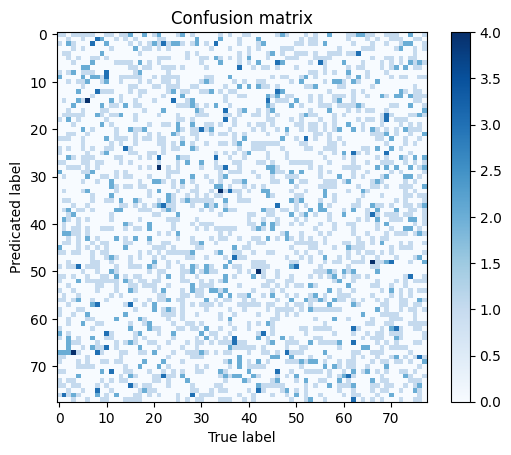

In [13]:
import matplotlib.pyplot as plt

plt.imshow(cm, interpolation='nearest', cmap= plt.cm.Blues)
plt.title('Confusion matrix')
plt.colorbar()
plt.xlabel('True label')
plt.ylabel('Predicated label')
plt.show()

In [14]:
from sklearn.metrics import classification_report
print(classification_report(test_labels, pred_labels))

              precision    recall  f1-score   support

           0       0.03      0.02      0.02        48
           1       0.00      0.00      0.00        30
           2       0.05      0.04      0.04        50
           3       0.03      0.04      0.03        25
           4       0.00      0.00      0.00        26
           5       0.00      0.00      0.00        32
           6       0.00      0.00      0.00        40
           7       0.00      0.00      0.00        33
           8       0.00      0.00      0.00        22
           9       0.03      0.02      0.03        42
          10       0.05      0.06      0.05        36
          11       0.00      0.00      0.00        28
          12       0.00      0.00      0.00        36
          13       0.04      0.03      0.03        35
          14       0.00      0.00      0.00        36
          15       0.00      0.00      0.00        41
          16       0.00      0.00      0.00        30
          17       0.00    

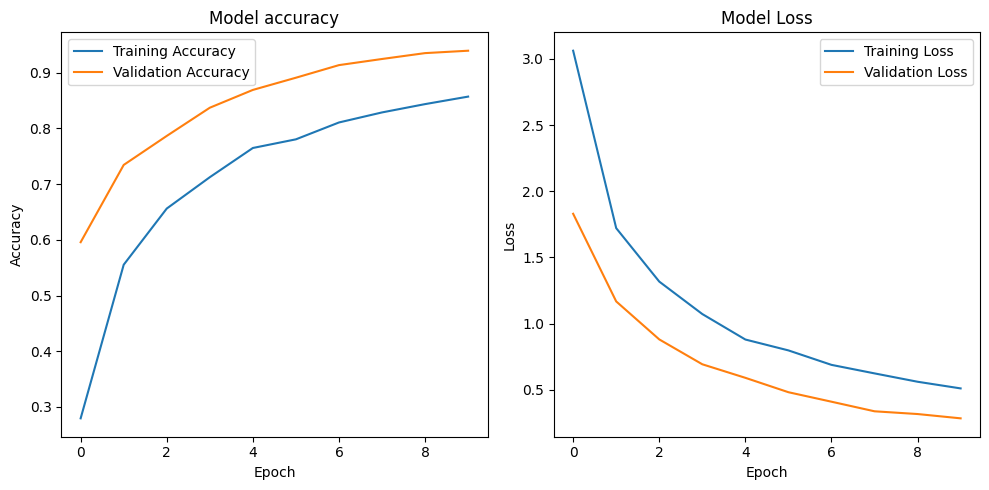

In [16]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()

# Plot training & validation loss values
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()


In [17]:
# predict with new images
import numpy as np
img = tf.keras.preprocessing.image.load_img(
    r"path/to/some-leaf.jpg", target_size=(299, 299)
)

img_array = tf.keras.preprocessing.image.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)  # Create a batch


predictions = model.predict(img_array)
score = tf.nn.sigmoid(predictions[0])
print(
    "This image most likely belongs to {} with a {:.2f} percent confidence."
    .format(labels[np.argmax(score)], 100 * np.max(score))
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
This image most likely belongs to Aloevera with a 72.73 percent confidence.


In [18]:
# Save the model architecture as JSON
model_json = model.to_json()
with open("model_architecture.json", "w") as json_file:
    json_file.write(model_json)

# Save the model weights
# Save the model weights
model.save_weights("model_weights.weights.h5")

